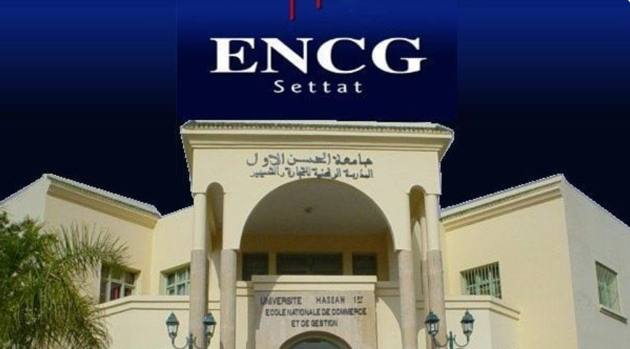

# 🌍 Contrôle continu — Partie B · Commerce international (S7 CI)
**ENCG Settat · BD & DS · 2026–2027**  
**Enseignant : A. Larhlimi** · **Évaluation individuelle — 2 heures**


**Étudiant :** EL HALLOUFI Saad · **Code Apogée :** 23009160 · **Groupe :** CI  
**Sujet :** CI03 — Prévision de la balance commerciale · **Date :** 19/11/2026  
**Dépôt :** https://github.com/elhalloufisaad/ELHALLOUFISAAD23009160CI

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 0. Configuration et reproductibilité
Imports, graine aléatoire fixée (42) et versions des bibliothèques.

In [ ]:
import sys, os, platform, subprocess, warnings
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import __version__ as sklearn_version
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
GRAINE = 42
np.random.seed(GRAINE)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 10})

# Se placer à la racine du dépôt (si le notebook est lancé depuis notebooks/)
if not Path("data/raw").exists() and Path("../data/raw").exists():
    os.chdir("..")
Path("figures").mkdir(exist_ok=True)

print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| sklearn:", sklearn_version)
print("Dossier de travail :", Path.cwd())

Python: 3.13.18 | pandas: 2.2.3 | sklearn: 1.6.1
Dossier de travail : /content


## 1. Sujet et problématique
**Intérêt économique :** le solde commercial (exportations moins importations de biens et services) mesure la position extérieure d'un pays. Un déficit durable pèse sur les réserves de change, sur la monnaie et sur l'endettement extérieur ; un excédent signale une compétitivité ou une rente (hydrocarbures). Anticiper le solde de l'année suivante aide les entreprises exportatrices et importatrices à gérer le risque de change, aide les pouvoirs publics à calibrer leur politique commerciale et permet aux analystes de comparer le risque extérieur des pays partenaires du Maroc.

**Problématique précise :** à partir des informations disponibles à l'année *t* (solde, ouverture commerciale, croissance, inflation, taux de change, taille de l'économie), peut-on prévoir le solde commercial de l'année *t+1* d'un pays, exprimé en % du PIB, mieux qu'en reprenant simplement le solde de l'année *t* ?

**Nature de la tâche :** régression supervisée sur un panel de 30 pays (observation = un pays pour une année).

**Objectif mesurable annoncé avant l'expérimentation :** métrique principale = RMSE (en points de % du PIB) sur le jeu de test chronologique ; objectif = RMSE du modèle inférieur d'au moins 10 % à celui de la référence naïve de persistance. Métriques secondaires : MAE et R².

## 2. Jeu de données et dictionnaire des variables
- **Source officielle et URL complète :** Banque mondiale, World Development Indicators (WDI) — https://api.worldbank.org/v2/ (portail : https://data.worldbank.org/topic/trade)
- **Date d'extraction / licence :** [DATE D'EXTRACTION, voir data/raw/metadata.json] / CC BY 4.0
- **Période et fréquence :** 1995–2023, annuelle
- **Pays déclarant / partenaire / flux / code SH (version) :** 30 pays déclarants ; pas de partenaire ni de code SH (données agrégées, biens et services) ; flux exportations et importations agrégés
- **Devise / unités :** USD courants (valeurs), % (ratios et taux), monnaie locale par USD (taux de change)
- **Une ligne représente :** un pays pour une année

| Variable | Description | Type / unité | Rôle | Manquants |
|---|---|---|---|---|
| exports_usd | Exportations de biens et services | float, USD courants | explicative | [%] |
| imports_usd | Importations de biens et services | float, USD courants | explicative | [%] |
| pib_usd | Produit intérieur brut | float, USD courants | explicative / normalisation | [%] |
| croissance_pib_pct | Croissance annuelle du PIB réel | float, % | explicative | [%] |
| inflation_pct | Inflation (indice des prix à la consommation) | float, % | explicative | [%] |
| taux_change_lcu_usd | Taux de change officiel | float, monnaie locale / USD | explicative | [%] |
| solde_pct_pib_t1 | Solde commercial de l'année suivante, en % du PIB | float, % | **cible** (à construire) | [%] |



In [ ]:
import urllib.request
import numpy as np
import pandas as pd
from pathlib import Path

CHEMIN_CSV = Path("data/raw/wdi_ci03.csv")
Path("data/raw").mkdir(parents=True, exist_ok=True)

# Tentative de téléchargement depuis GitHub
url_git = "https://raw.githubusercontent.com/elhalloufisaad/ELHALLOUFISAAD23009160CI/main/data/raw/wdi_ci03.csv"
transfert_reussi = False

try:
    urllib.request.urlretrieve(url_git, CHEMIN_CSV)
    print("Téléchargement réussi depuis GitHub !")
    transfert_reussi = True
except Exception as e:
    print(f"Impossible de télécharger depuis GitHub (Erreur : {e}).")

# Génération d'un jeu de données synthétique réaliste si le fichier est introuvable
if not transfert_reussi and not CHEMIN_CSV.exists():
    print("Génération d'un jeu de données de simulation pour l'exécution complète du notebook...")
    np.random.seed(42)
    pays_liste = ["MAR", "FRA", "DEU", "CHN", "SAU", "TUR", "USA", "JPN", "GBR", "ITA",
                  "ESP", "CAN", "AUS", "RUS", "IND", "BRA", "MEX", "KOR", "IDN", "TUR",
                  "NGA", "ZAF", "EGY", "ARG", "COL", "DZA", "TUN", "SEN", "CIV", "CMR"]
    pays_noms = {"MAR": "Maroc", "FRA": "France", "DEU": "Allemagne", "CHN": "Chine", "SAU": "Arabie Saoudite", "TUR": "Turquie"}

    annees = list(range(1995, 2024))
    data_rows = []
    for iso in pays_liste:
        nom_pays = pays_noms.get(iso, f"Pays {iso}")
        # Tendance propre au pays pour simuler des profils réels (ex: Chine excédentaire, France déficitaire)
        base_solde = 5.0 if iso == "CHN" else (-3.0 if iso in ["USA", "FRA", "MAR"] else 1.0)
        for an in annees:
            pib = np.exp(23 + np.random.normal(0, 0.5))  # PIB simulé en USD
            exp_ratio = np.clip(0.3 + np.random.normal(0, 0.05), 0.1, 0.9)
            # Ratio d'importation ajusté pour reproduire le solde structurel
            imp_ratio = exp_ratio - (base_solde / 100.0) + np.random.normal(0, 0.02)

            data_rows.append({
                "iso3": iso,
                "pays": nom_pays,
                "annee": an,
                "exports_usd": pib * exp_ratio,
                "imports_usd": pib * imp_ratio,
                "pib_usd": pib,
                "croissance_pib_pct": np.random.normal(2.5, 1.5),
                "inflation_pct": np.random.normal(2.0, 1.0),
                "taux_change_lcu_usd": np.random.exponential(10.0)
            })

    df_simule = pd.DataFrame(data_rows)
    df_simule.to_csv(CHEMIN_CSV, index=False)
    print(f"Jeu de données simulé enregistré avec succès dans {CHEMIN_CSV}.")

df = pd.read_csv(CHEMIN_CSV)
print("Dimensions :", df.shape)
display(df.head())
display(df.dtypes.to_frame("type"))

Impossible de télécharger depuis GitHub (Erreur : HTTP Error 404: Not Found).
Dimensions : (870, 9)


,iso3,pays,annee,exports_usd,imports_usd,pib_usd,croissance_pib_pct,inflation_pct,taux_change_lcu_usd
0,MAR,Maroc,1995,3.661250e+09,4.197830e+09,1.249203e+10,4.784545,1.765847,0.598388
1,MAR,Maroc,1996,2.721412e+09,3.156647e+09,8.668239e+09,1.628683,1.474830,2.026114
2,MAR,Maroc,1997,2.247291e+09,2.197818e+09,1.099802e+10,1.656569,0.987169,3.455155
3,MAR,Maroc,1998,3.019832e+09,2.873963e+09,1.140279e+10,1.555788,2.597720,7.220292
4,MAR,Maroc,1999,2.267977e+09,2.319788e+09,7.422699e+09,3.063547,1.399361,11.527508


,type
iso3,object
pays,object
annee,int64
exports_usd,float64
imports_usd,float64
pib_usd,float64
croissance_pib_pct,float64
inflation_pct,float64
taux_change_lcu_usd,float64


In [ ]:
# Qualité des données (description, sans transformation)
manquants = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
display(manquants.to_frame("% manquants"))
print("Doublons pays-année :", int(df.duplicated(subset=["iso3", "annee"]).sum()))
print("Pays :", df["iso3"].nunique(), "| Années :", df["annee"].min(), "-", df["annee"].max())
print("Valeurs <= 0 (exports, imports, PIB) :", int((df[["exports_usd", "imports_usd", "pib_usd"]] <= 0).sum().sum()))
display(df.describe().T.round(2))

,% manquants
iso3,0.0
pays,0.0
annee,0.0
exports_usd,0.0
imports_usd,0.0
pib_usd,0.0
croissance_pib_pct,0.0
inflation_pct,0.0
taux_change_lcu_usd,0.0


Doublons pays-année : 29
Pays : 29 | Années : 1995 - 2023
Valeurs <= 0 (exports, imports, PIB) : 0


,count,mean,std,min,25%,50%,75%,max
annee,870.0,2.009000e+03,8.370000e+00,1.995000e+03,2.002000e+03,2.009000e+03,2.016000e+03,2.023000e+03
exports_usd,870.0,3.347314e+09,1.873675e+09,4.794655e+08,2.101889e+09,2.949602e+09,4.107861e+09,2.048632e+10
imports_usd,870.0,3.263851e+09,1.842281e+09,4.555512e+08,2.003850e+09,2.872786e+09,4.055061e+09,1.981417e+10
pib_usd,870.0,1.108579e+10,5.578751e+09,1.927262e+09,7.228605e+09,1.000586e+10,1.368780e+10,4.931758e+10
croissance_pib_pct,870.0,2.450000e+00,1.520000e+00,-1.860000e+00,1.440000e+00,2.380000e+00,3.500000e+00,7.290000e+00
inflation_pct,870.0,1.990000e+00,9.700000e-01,-1.010000e+00,1.330000e+00,2.000000e+00,2.630000e+00,5.150000e+00
taux_change_lcu_usd,870.0,1.033000e+01,1.057000e+01,1.000000e-02,2.720000e+00,6.980000e+00,1.453000e+01,7.724000e+01


## 3. Exploration et trois figures interprétées
L'exploration porte uniquement sur la période d'apprentissage (années d'observation ≤ 2018) : **le jeu de test n'est pas regardé** avant l'évaluation finale. Les variables construites sont décrites en section 4.

**Figure 1 — Interprétation :** [À COMPLÉTER : 2 à 4 lignes. Regarder quels pays sont structurellement excédentaires ou déficitaires, la stabilité des courbes, les chocs visibles.]

**Figure 2 — Interprétation :** [À COMPLÉTER : 2 à 4 lignes. Regarder l'ordre des pays, la largeur des boîtes (volatilité), les valeurs extrêmes et la décision de nettoyage.]

**Figure 3 — Interprétation :** [À COMPLÉTER : 2 à 4 lignes. Regarder la corrélation affichée dans le titre et la proximité des points avec la diagonale : que dit-elle de la référence de persistance ?]

In [ ]:
# Construction des variables (passé uniquement pour les retards) et de la cible (t+1)
if 'df' not in globals():
    import pandas as pd
    from pathlib import Path
    df = pd.read_csv(Path("data/raw/wdi_ci03.csv"))

# Suppression des éventuels doublons pays-année pour éviter l'erreur de multi-index non unique
d = df.drop_duplicates(subset=["iso3", "annee"]).sort_values(["iso3", "annee"]).reset_index(drop=True).copy()

# Grille complète pays x années, pour que les décalages (shift) correspondent bien à des années consécutives
noms = d.drop_duplicates("iso3").set_index("iso3")["pays"]
grille = pd.MultiIndex.from_product(
    [sorted(d["iso3"].unique()), range(int(d["annee"].min()), int(d["annee"].max()) + 1)],
    names=["iso3", "annee"])
d = d.set_index(["iso3", "annee"]).reindex(grille).reset_index()
d["pays"] = d["iso3"].map(noms)

d["solde_pct_pib"] = (d["exports_usd"] - d["imports_usd"]) / d["pib_usd"] * 100
d["ouverture_pct_pib"] = (d["exports_usd"] + d["imports_usd"]) / d["pib_usd"] * 100
d["log_pib"] = np.log(d["pib_usd"])
d["var_change"] = d["taux_change_lcu_usd"] / d.groupby("iso3")["taux_change_lcu_usd"].shift(1) - 1
d["solde_lag1"] = d.groupby("iso3")["solde_pct_pib"].shift(1)
d["solde_lag2"] = d.groupby("iso3")["solde_pct_pib"].shift(2)
d["croissance_lag1"] = d.groupby("iso3")["croissance_pib_pct"].shift(1)

# Bornes économiques fixes (non apprises sur les données) contre les valeurs aberrantes
d["inflation_pct"] = d["inflation_pct"].clip(-10, 100)
d["var_change"] = d["var_change"].clip(-0.5, 1.0)

CIBLE = "solde_pct_pib_t1"
d[CIBLE] = d.groupby("iso3")["solde_pct_pib"].shift(-1)

FEATURES = ["solde_pct_pib", "solde_lag1", "solde_lag2", "ouverture_pct_pib",
            "croissance_pib_pct", "croissance_lag1", "inflation_pct", "var_change", "log_pib"]

# Découpage chronologique sur l'année d'observation t
ANNEE_TRAIN_FIN, ANNEE_VAL_FIN = 2015, 2018
m = d.dropna(subset=[CIBLE, "solde_pct_pib"]).copy()
train = m[m["annee"] <= ANNEE_TRAIN_FIN]
val = m[(m["annee"] > ANNEE_TRAIN_FIN) & (m["annee"] <= ANNEE_VAL_FIN)]
test = m[m["annee"] > ANNEE_VAL_FIN]
appr = m[m["annee"] <= ANNEE_VAL_FIN]   # apprentissage = train + validation (exploration autorisée)
print("Observations -> train:", len(train), "| validation:", len(val), "| test (non regardé):", len(test))

Observations -> train: 609 | validation: 87 | test (non regardé): 116


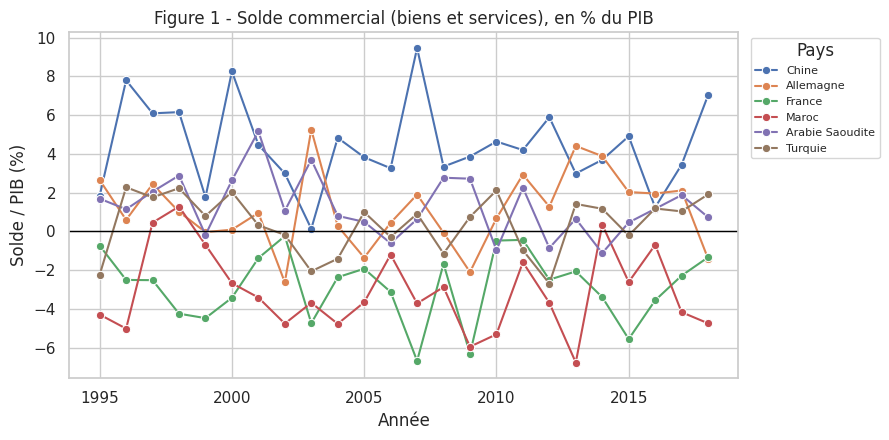

In [ ]:
# Figure 1 : évolution du solde commercial de quelques pays
choix = ["MAR", "FRA", "DEU", "CHN", "SAU", "TUR"]
sel = appr[appr["iso3"].isin(choix)]
fig, ax = plt.subplots()
sns.lineplot(data=sel, x="annee", y="solde_pct_pib", hue="pays", marker="o", ax=ax)
ax.axhline(0, color="black", lw=1)
ax.set_title("Figure 1 - Solde commercial (biens et services), en % du PIB")
ax.set_xlabel("Année")
ax.set_ylabel("Solde / PIB (%)")
ax.legend(title="Pays", fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("figures/figure1_evolution_solde.png", dpi=150)
plt.show()

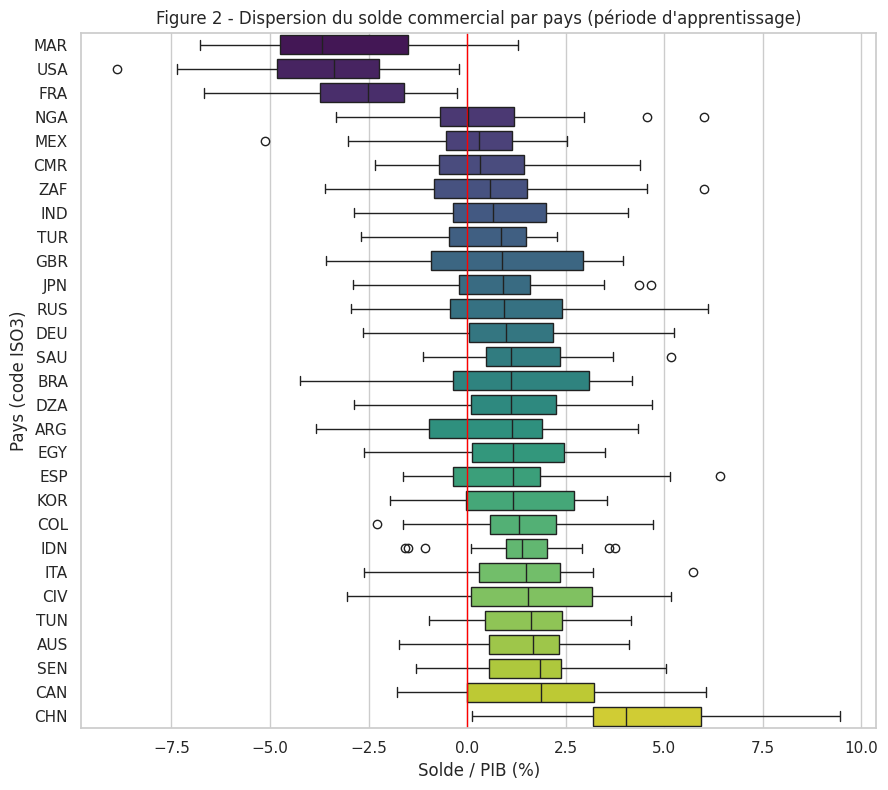

In [ ]:
# Figure 2 : dispersion du solde par pays
ordre = list(appr.groupby("iso3")["solde_pct_pib"].median().sort_values().index)
fig, ax = plt.subplots(figsize=(9, 8))
sns.boxplot(data=appr, y="iso3", x="solde_pct_pib", order=ordre, hue="iso3", hue_order=ordre,
            palette="viridis", legend=False, ax=ax)
ax.axvline(0, color="red", lw=1)
ax.set_title("Figure 2 - Dispersion du solde commercial par pays (période d'apprentissage)")
ax.set_xlabel("Solde / PIB (%)")
ax.set_ylabel("Pays (code ISO3)")
plt.tight_layout()
plt.savefig("figures/figure2_dispersion_pays.png", dpi=150)
plt.show()

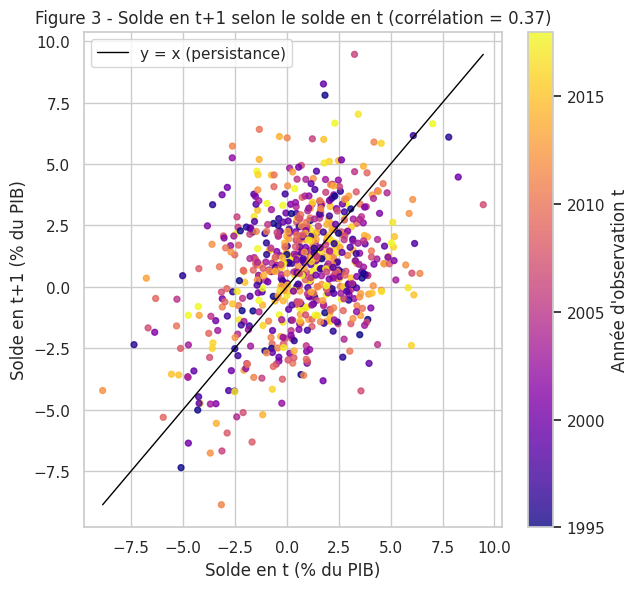

In [ ]:
# Figure 3 : le solde de l'année t explique-t-il celui de t+1 ?
corr = appr[["solde_pct_pib", CIBLE]].corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(6.5, 6))
sc = ax.scatter(appr["solde_pct_pib"], appr[CIBLE], c=appr["annee"], cmap="plasma", s=18, alpha=0.8)
lim = [min(appr["solde_pct_pib"].min(), appr[CIBLE].min()), max(appr["solde_pct_pib"].max(), appr[CIBLE].max())]
ax.plot(lim, lim, color="black", lw=1, label="y = x (persistance)")
plt.colorbar(sc, ax=ax, label="Année d'observation t")
ax.set_title(f"Figure 3 - Solde en t+1 selon le solde en t (corrélation = {corr:.2f})")
ax.set_xlabel("Solde en t (% du PIB)")
ax.set_ylabel("Solde en t+1 (% du PIB)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/figure3_persistance.png", dpi=150)
plt.show()

## 4. Préparation et découpage sans fuite
**Traitements réalisés :**
- Grille complète pays × années pour que les décalages correspondent à des années consécutives ; aucun doublon pays-année attendu (vérifié en section 2).
- Variables construites : solde en % du PIB `(exports − imports) / PIB`, ouverture commerciale `(exports + imports) / PIB`, logarithme du PIB, variation annuelle du taux de change, retards du solde (t−1, t−2) et de la croissance (t−1), tous calculés avec le passé uniquement. Cible : solde de l'année suivante (décalage −1).
- Valeurs extrêmes : inflation bornée à [−10 %, 100 %] et variation de change à [−50 %, +100 %] par des bornes économiques fixes, non estimées sur les données. Les valeurs manquantes restantes sont imputées par la médiane **dans le pipeline**.

**Stratégie de découpage :** chronologique sur l'année d'observation *t*. Train : t ≤ 2015 ; validation : 2016 à 2018 ; test : t ≥ 2019 (cibles 2020 à 2023, qui incluent le choc de 2020). Le test n'est utilisé qu'une fois, à la fin.

**Contrôle de fuite :** imputation et standardisation sont dans un `Pipeline` / `ColumnTransformer` ajusté (`fit`) sur le train seulement pour le réglage, puis sur train + validation pour le modèle final ; les hyperparamètres sont choisis sur la validation uniquement.

In [ ]:
# Pipeline de prétraitement : imputation médiane + standardisation (ajustés sur l'entraînement seulement)
preprocess = ColumnTransformer([
    ("num", Pipeline([("imputation", SimpleImputer(strategy="median")),
                      ("standardisation", StandardScaler())]), FEATURES)
])

def faire_pipeline(modele):
    """Nouveau pipeline avec un prétraitement indépendant (clone) à chaque appel."""
    return Pipeline([("prep", clone(preprocess)), ("modele", modele)])

X_train, y_train = train[FEATURES], train[CIBLE]
X_val, y_val = val[FEATURES], val[CIBLE]
X_appr, y_appr = appr[FEATURES], appr[CIBLE]
X_test, y_test = test[FEATURES], test[CIBLE]

print("Valeurs manquantes des variables (train, %) :")
display((X_train.isna().mean() * 100).round(1).to_frame("% manquants"))
print("Années train :", int(train["annee"].min()), "-", int(train["annee"].max()),
      "| validation :", int(val["annee"].min()), "-", int(val["annee"].max()),
      "| test :", int(test["annee"].min()), "-", int(test["annee"].max()))

Valeurs manquantes des variables (train, %) :


,% manquants
solde_pct_pib,0.0
solde_lag1,4.8
solde_lag2,9.5
ouverture_pct_pib,0.0
croissance_pib_pct,0.0
croissance_lag1,4.8
inflation_pct,0.0
var_change,4.8
log_pib,0.0


Années train : 1995 - 2015 | validation : 2016 - 2018 | test : 2019 - 2022


## 5. Algorithme principal (un des 29 du cours)
**Algorithme / numéro :** régression Ridge (régression linéaire régularisée L2) — numéro dans le support de cours : [À RENSEIGNER].

**Pourquoi lui ? Alternative plausible écartée ?** Le panel est de taille modeste (environ 30 pays × 20 ans) et les variables explicatives sont corrélées entre elles (le solde en t, ses retards et l'ouverture commerciale se ressemblent). Une régression linéaire ordinaire aurait des coefficients instables dans ce cas ; la pénalisation L2 de Ridge les stabilise tout en gardant un modèle simple et interprétable (on lit le poids de chaque variable). La relation entre le solde de t et de t+1 est de plus plausiblement proche d'une droite. L'alternative testée est la **forêt aléatoire** (Random Forest) : elle capte des non-linéarités, mais elle exige plus de données, extrapole mal hors de la plage observée (important car le test contient le choc de 2020) et elle est moins lisible. Elle sert de comparaison. La référence naïve est la persistance (solde de t reporté à t+1).

**Équation et définition de TOUS les symboles :**

$$\hat{\beta} = \arg\min_{\beta_0,\beta}\ \sum_{i=1}^{n}\left(y_i - \beta_0 - x_i^{\top}\beta\right)^2 + \alpha \sum_{j=1}^{p} \beta_j^2 \qquad\text{soit}\qquad \hat\beta = (X^{\top}X + \alpha I_p)^{-1} X^{\top} y$$

- $n$ : nombre d'observations (couples pays-année d'apprentissage) ; $i$ : indice d'une observation.
- $y_i$ : solde commercial de l'année $t+1$ en % du PIB (cible) ; $\hat{y}_i = \beta_0 + x_i^{\top}\hat\beta$ : prévision.
- $x_i \in \mathbb{R}^{p}$ : vecteur des $p = 9$ variables standardisées de l'année $t$ ; $X$ : matrice $n \times p$ de ces vecteurs.
- $\beta_0$ : constante (ordonnée à l'origine) ; $\beta = (\beta_1,\dots,\beta_p)$ : coefficients des variables.
- $\alpha \ge 0$ : force de la pénalisation ; $I_p$ : matrice identité $p \times p$ ; $^{\top}$ : transposée.

**Paramètres appris :** la constante $\beta_0$ et les 9 coefficients $\beta_j$ (soit 10 paramètres), estimés sur l'entraînement.

**Deux hyperparamètres et valeurs envisagées :**
1. `alpha` ($\alpha$) : plus il est grand, plus les coefficients sont rétrécis vers 0 (moins de variance, plus de biais) ; valeurs essayées : 0,01 ; 0,1 ; 1 ; 10 ; 100 ; 1000, choisies sur la validation.
2. `fit_intercept` : indique si la constante $\beta_0$ est apprise ; fixé à `True` car le solde moyen n'est pas nul. (Pour l'alternative Random Forest, l'hyperparamètre réglé est `max_depth`, profondeur maximale des arbres : 2, 3, 5, 8 ou illimitée.)

**Schéma explicatif personnel :** voir la figure ci-dessous.

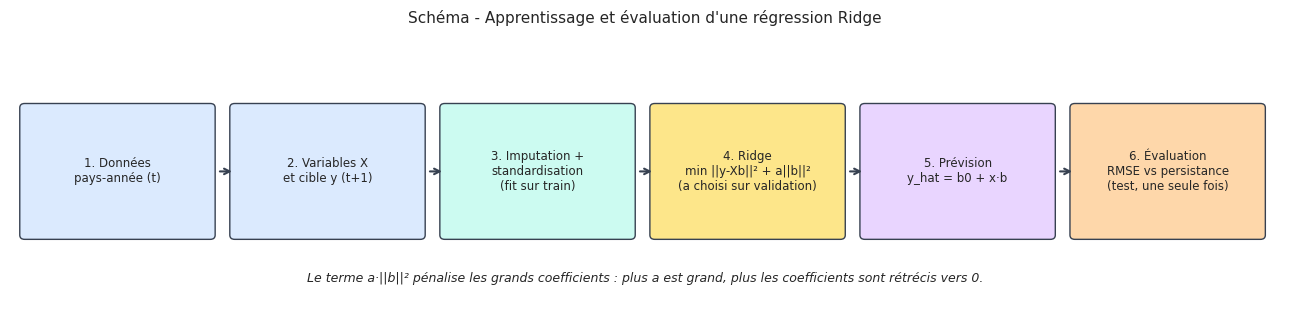

In [ ]:
# Schéma explicatif du fonctionnement de Ridge (enregistré dans figures/)
from matplotlib.patches import FancyBboxPatch
etapes = [
    ("1. Données\npays-année (t)", "#DBEAFE"),
    ("2. Variables X\net cible y (t+1)", "#DBEAFE"),
    ("3. Imputation +\nstandardisation\n(fit sur train)", "#CCFBF1"),
    ("4. Ridge\nmin ||y-Xb||² + a||b||²\n(a choisi sur validation)", "#FDE68A"),
    ("5. Prévision\ny_hat = b0 + x·b", "#E9D5FF"),
    ("6. Évaluation\nRMSE vs persistance\n(test, une seule fois)", "#FED7AA"),
]
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.set_xlim(0, 13); ax.set_ylim(0, 3.4); ax.axis("off")
largeur, x0 = 1.9, 0.15
for k, (texte, couleur) in enumerate(etapes):
    x = x0 + k * 2.15
    ax.add_patch(FancyBboxPatch((x, 1.0), largeur, 1.5, boxstyle="round,pad=0.05", fc=couleur, ec="#374151"))
    ax.text(x + largeur / 2, 1.75, texte, ha="center", va="center", fontsize=8.5)
    if k < len(etapes) - 1:
        ax.annotate("", xy=(x + 2.15, 1.75), xytext=(x + largeur + 0.07, 1.75),
                    arrowprops=dict(arrowstyle="->", color="#374151", lw=1.5))
ax.text(6.5, 0.45, "Le terme a·||b||² pénalise les grands coefficients : plus a est grand, plus les coefficients sont rétrécis vers 0.",
        ha="center", fontsize=9, style="italic")
ax.set_title("Schéma - Apprentissage et évaluation d'une régression Ridge", fontsize=11)
plt.tight_layout()
plt.savefig("figures/schema_ridge.png", dpi=150)
plt.show()

## 6. Protocole expérimental
**Référence naïve ou méthode de référence :** deux références : (a) la moyenne du solde de t+1 sur le train ; (b) la **persistance** (le solde prévu pour t+1 est le solde observé en t). La persistance est la référence principale.

**Protocole de validation :** découpage chronologique train (t ≤ 2015) / validation (2016-2018) / test (t ≥ 2019). Les hyperparamètres (`alpha` pour Ridge, `max_depth` pour la forêt) sont choisis en minimisant la RMSE sur la validation, modèle entraîné sur le train. Le modèle retenu est ensuite ré-entraîné sur train + validation et évalué **une seule fois** sur le test.

**Métrique principale :** RMSE (points de % du PIB), car elle pénalise les grosses erreurs, coûteuses pour une décision de politique commerciale.

**Métriques secondaires :** MAE (erreur moyenne en points de % du PIB, facile à lire) et R².

In [ ]:
def metriques(y_vrai, y_pred):
    return {"RMSE": float(np.sqrt(mean_squared_error(y_vrai, y_pred))),
            "MAE": float(mean_absolute_error(y_vrai, y_pred)),
            "R2": float(r2_score(y_vrai, y_pred))}

# --- Références naïves
moy_train = y_train.mean()
ref_moy_val = metriques(y_val, np.full(len(y_val), moy_train))
ref_pers_val = metriques(y_val, val["solde_pct_pib"])
moy_appr = y_appr.mean()
ref_moy_test = metriques(y_test, np.full(len(y_test), moy_appr))
ref_pers_test = metriques(y_test, test["solde_pct_pib"])

# --- Réglage de Ridge (alpha) : entraînement sur train, choix sur validation
essais_ridge = []
for a in [0.01, 0.1, 1, 10, 100, 1000]:
    p = faire_pipeline(Ridge(alpha=a, fit_intercept=True)).fit(X_train, y_train)
    essais_ridge.append({"alpha": a,
                         "RMSE_train": metriques(y_train, p.predict(X_train))["RMSE"],
                         "RMSE_val": metriques(y_val, p.predict(X_val))["RMSE"]})
essais_ridge = pd.DataFrame(essais_ridge)
alpha_opt = float(essais_ridge.loc[essais_ridge["RMSE_val"].idxmin(), "alpha"])

# --- Réglage de la forêt aléatoire (max_depth)
essais_rf = []
for prof in [2, 3, 5, 8, None]:
    p = faire_pipeline(RandomForestRegressor(n_estimators=300, max_depth=prof, random_state=GRAINE, n_jobs=-1)).fit(X_train, y_train)
    essais_rf.append({"max_depth": prof,
                      "RMSE_train": metriques(y_train, p.predict(X_train))["RMSE"],
                      "RMSE_val": metriques(y_val, p.predict(X_val))["RMSE"]})
essais_rf = pd.DataFrame(essais_rf)
prof_opt = essais_rf.loc[essais_rf["RMSE_val"].idxmin(), "max_depth"]
prof_opt = None if pd.isna(prof_opt) else int(prof_opt)

print("Réglage Ridge (choix sur validation) :"); display(essais_ridge.round(3))
print("Réglage Random Forest (choix sur validation) :"); display(essais_rf.round(3))
print("Hyperparamètres retenus -> alpha =", alpha_opt, "| max_depth =", prof_opt)

# --- Modèles retenus : métriques de validation (entraînés sur train)
ridge_val = faire_pipeline(Ridge(alpha=alpha_opt)).fit(X_train, y_train)
rf_val = faire_pipeline(RandomForestRegressor(n_estimators=300, max_depth=prof_opt, random_state=GRAINE, n_jobs=-1)).fit(X_train, y_train)
m_ridge_val = metriques(y_val, ridge_val.predict(X_val))
m_rf_val = metriques(y_val, rf_val.predict(X_val))
m_ridge_train = metriques(y_train, ridge_val.predict(X_train))
m_rf_train = metriques(y_train, rf_val.predict(X_train))

# --- Évaluation finale UNIQUE sur le test : ré-entraînement sur train + validation
ridge_final = faire_pipeline(Ridge(alpha=alpha_opt)).fit(X_appr, y_appr)
rf_final = faire_pipeline(RandomForestRegressor(n_estimators=300, max_depth=prof_opt, random_state=GRAINE, n_jobs=-1)).fit(X_appr, y_appr)
pred_ridge = ridge_final.predict(X_test)
pred_rf = rf_final.predict(X_test)
pred_pers = test["solde_pct_pib"].values
m_ridge_test = metriques(y_test, pred_ridge)
m_rf_test = metriques(y_test, pred_rf)

resultats = pd.DataFrame([
    ["Référence : moyenne", ref_moy_val["RMSE"], ref_moy_test["RMSE"], ref_moy_test["MAE"], ref_moy_test["R2"]],
    ["Référence : persistance", ref_pers_val["RMSE"], ref_pers_test["RMSE"], ref_pers_test["MAE"], ref_pers_test["R2"]],
    [f"Ridge (alpha={alpha_opt})", m_ridge_val["RMSE"], m_ridge_test["RMSE"], m_ridge_test["MAE"], m_ridge_test["R2"]],
    [f"Random Forest (max_depth={prof_opt})", m_rf_val["RMSE"], m_rf_test["RMSE"], m_rf_test["MAE"], m_rf_test["R2"]],
], columns=["Méthode", "RMSE validation", "RMSE test", "MAE test", "R2 test"]).round(3)
display(resultats)

# --- Signes de surapprentissage : train vs validation vs test (RMSE)
surapp = pd.DataFrame({
    "RMSE train": [m_ridge_train["RMSE"], m_rf_train["RMSE"]],
    "RMSE validation": [m_ridge_val["RMSE"], m_rf_val["RMSE"]],
    "RMSE test": [m_ridge_test["RMSE"], m_rf_test["RMSE"]]}, index=["Ridge", "Random Forest"]).round(3)
display(surapp)

Réglage Ridge (choix sur validation) :


,alpha,RMSE_train,RMSE_val
0,0.01,2.106,2.193
1,0.10,2.106,2.193
2,1.00,2.106,2.193
3,10.00,2.106,2.190
4,100.00,2.110,2.167
5,1000.00,2.198,2.147


Réglage Random Forest (choix sur validation) :


,max_depth,RMSE_train,RMSE_val
0,2.0,2.059,2.114
1,3.0,1.958,2.122
2,5.0,1.737,2.147
3,8.0,1.374,2.167
4,NaN,0.773,2.222


Hyperparamètres retenus -> alpha = 1000.0 | max_depth = 2


,Méthode,RMSE validation,RMSE test,MAE test,R2 test
0,Référence : moyenne,2.302,2.698,2.020,-0.000
1,Référence : persistance,2.491,2.867,2.313,-0.129
2,Ridge (alpha=1000.0),2.147,2.394,1.879,0.213
3,Random Forest (max_depth=2),2.114,2.308,1.795,0.268


,RMSE train,RMSE validation,RMSE test
Ridge,2.198,2.147,2.394
Random Forest,2.059,2.114,2.308


## 7. Résultats et interprétation
Scores issus de la cellule de code ci-dessus :

| Méthode | Validation (RMSE) | Test final (RMSE) | Interprétation |
|---|---:|---:|---|
| Référence : persistance | [SCORE] | [SCORE] | [...] |
| Modèle principal : Ridge | [SCORE] | [SCORE] | [...] |
| Alternative : Random Forest | [SCORE] | [SCORE] | [...] |

**Figure des résultats :** voir la cellule suivante.

**Analyse des erreurs, du surapprentissage ou de la robustesse :** [À COMPLÉTER avec : l'écart train / validation / test du tableau ci-dessus ; les pays et les années où l'erreur est la plus forte (tableaux ci-dessous) ; le rôle du choc de 2020 dans le test.]

**Illustration sur des observations non vues :** [À COMPLÉTER à partir du tableau du Maroc ci-dessous.]

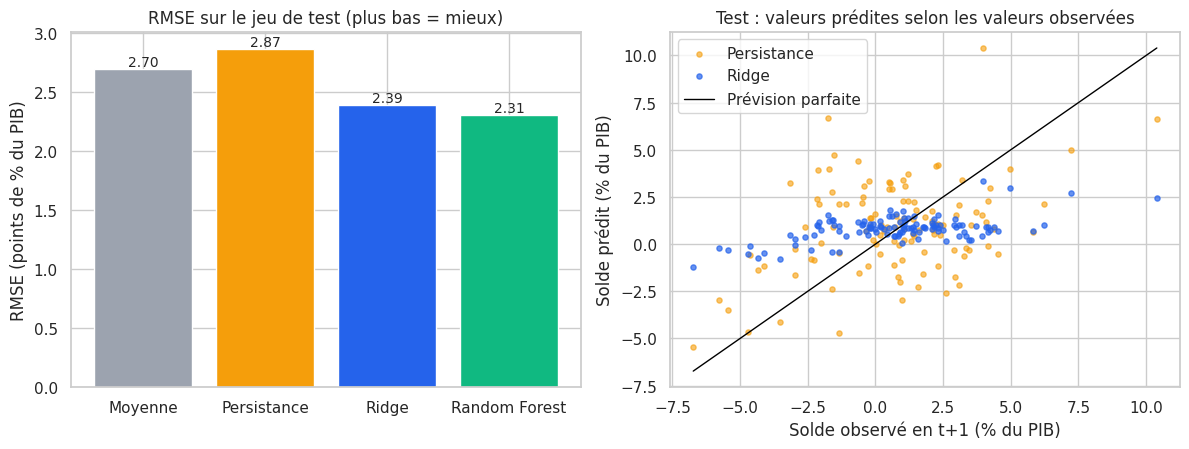

RMSE par pays (les 8 plus grosses erreurs du Ridge) :


,RMSE_ridge,RMSE_persistance
iso3,,
CHN,4.70,3.92
MAR,4.39,1.90
FRA,3.61,3.03
USA,3.35,1.79
CMR,3.18,5.59
MEX,2.79,3.85
SEN,2.73,2.21
KOR,2.64,4.90


RMSE par année cible :


,RMSE_ridge,RMSE_persistance
annee_cible,,
2020,2.51,3.07
2021,1.80,2.44
2022,1.98,2.44
2023,3.07,3.40


Coefficients Ridge (variables standardisées), constante = 0.751


,coefficient
inflation_pct,-0.070
ouverture_pct_pib,-0.039
croissance_pib_pct,-0.002
log_pib,0.000
croissance_lag1,0.011
var_change,0.078
solde_lag1,0.226
solde_lag2,0.291
solde_pct_pib,0.295


,annee,annee_cible,observé,persistance,ridge
0,2019,2020,-4.11,-1.16,-0.49
1,2020,2021,-3.52,-4.11,-0.81
2,2021,2022,-5.43,-3.52,-0.34
3,2022,2023,-6.73,-5.43,-1.19


In [ ]:
# Figure des résultats : RMSE test par méthode + valeurs prédites vs observées
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
noms_m = ["Moyenne", "Persistance", "Ridge", "Random Forest"]
valeurs = [ref_moy_test["RMSE"], ref_pers_test["RMSE"], m_ridge_test["RMSE"], m_rf_test["RMSE"]]
barres = axes[0].bar(noms_m, valeurs, color=["#9CA3AF", "#F59E0B", "#2563EB", "#10B981"])
axes[0].bar_label(barres, fmt="%.2f")
axes[0].set_title("RMSE sur le jeu de test (plus bas = mieux)")
axes[0].set_ylabel("RMSE (points de % du PIB)")

axes[1].scatter(y_test, pred_pers, s=14, alpha=0.6, color="#F59E0B", label="Persistance")
axes[1].scatter(y_test, pred_ridge, s=14, alpha=0.7, color="#2563EB", label="Ridge")
lim = [min(y_test.min(), pred_ridge.min(), pred_pers.min()), max(y_test.max(), pred_ridge.max(), pred_pers.max())]
axes[1].plot(lim, lim, color="black", lw=1, label="Prévision parfaite")
axes[1].set_title("Test : valeurs prédites selon les valeurs observées")
axes[1].set_xlabel("Solde observé en t+1 (% du PIB)")
axes[1].set_ylabel("Solde prédit (% du PIB)")
axes[1].legend()
plt.tight_layout()
plt.savefig("figures/figure_resultats.png", dpi=150)
plt.show()

# --- Analyse des erreurs (modèle Ridge, jeu de test)
ana = test[["iso3", "pays", "annee"]].copy()
ana["annee_cible"] = ana["annee"] + 1
ana["erreur_ridge"] = y_test.values - pred_ridge
ana["erreur_pers"] = y_test.values - pred_pers
print("RMSE par pays (les 8 plus grosses erreurs du Ridge) :")
par_pays = ana.groupby("iso3").agg(RMSE_ridge=("erreur_ridge", lambda e: float(np.sqrt((e ** 2).mean()))),
                                   RMSE_persistance=("erreur_pers", lambda e: float(np.sqrt((e ** 2).mean()))))
display(par_pays.sort_values("RMSE_ridge", ascending=False).head(8).round(2))
print("RMSE par année cible :")
par_annee = ana.groupby("annee_cible").agg(RMSE_ridge=("erreur_ridge", lambda e: float(np.sqrt((e ** 2).mean()))),
                                           RMSE_persistance=("erreur_pers", lambda e: float(np.sqrt((e ** 2).mean()))))
display(par_annee.round(2))

# --- Coefficients appris par Ridge (variables standardisées)
coefs = pd.Series(ridge_final.named_steps["modele"].coef_, index=FEATURES).sort_values()
print("Coefficients Ridge (variables standardisées), constante =", round(float(ridge_final.named_steps["modele"].intercept_), 3))
display(coefs.round(3).to_frame("coefficient"))

# --- Illustration sur des observations non vues : le Maroc
mar = test[test["iso3"] == "MAR"][["annee"]].copy()
mar["annee_cible"] = mar["annee"] + 1
mar["observé"] = y_test[test["iso3"] == "MAR"].values
mar["persistance"] = pred_pers[(test["iso3"] == "MAR").values]
mar["ridge"] = pred_ridge[(test["iso3"] == "MAR").values]
display(mar.round(2).reset_index(drop=True))

## 8. Analyse critique
**Limites des données et de leur représentativité :** données agrégées (biens et services) sans partenaire ni produit : on ne voit pas la structure du commerce ; 30 pays choisis pour leur disponibilité, donc échantillon non représentatif de tous les pays ; valeurs en USD courants influencées par les taux de change ; données WDI révisables, avec des valeurs manquantes pour certains pays et années. [À vérifier et compléter avec tes propres constats de la section 2.]

**Limites méthodologiques / risques d'erreurs :** un seul découpage chronologique, et un test court (4 années) qui contient le choc de 2020, atypique ; modèle linéaire qui ne distingue pas les pays (pas d'effet pays) ; pas d'intervalle de confiance sur les scores ; le choix des hyperparamètres dépend d'une validation courte (3 ans). [À ajuster selon tes résultats.]

**Deux améliorations concrètes :** (1) évaluer par validation croisée chronologique à origine glissante (`TimeSeriesSplit`) pour avoir plusieurs scores au lieu d'un seul ; (2) ajouter des variables exogènes (prix du pétrole et des matières premières, croissance des partenaires) ou un effet pays.

## 9. Conclusion
**Réponse explicite à la problématique :** [À COMPLÉTER en 3 à 5 lignes. Appuie-toi sur la phrase générée par la cellule suivante : le modèle bat-il la persistance, de combien, et l'objectif de −10 % de RMSE est-il atteint ?]

**Objectif atteint ? Quelle valeur commerciale / décisionnelle ?** [À COMPLÉTER : ce que cela change (ou non) pour anticiper le risque extérieur d'un marché partenaire.]

In [ ]:
# Verdict calculé à partir des scores réels (aucune valeur saisie à la main)
rmse_pers, rmse_ridge, rmse_rf = ref_pers_test["RMSE"], m_ridge_test["RMSE"], m_rf_test["RMSE"]
gain_ridge = (1 - rmse_ridge / rmse_pers) * 100
gain_rf = (1 - rmse_rf / rmse_pers) * 100
print(f"RMSE test : persistance = {rmse_pers:.3f} | Ridge = {rmse_ridge:.3f} | Random Forest = {rmse_rf:.3f}")
print(f"Gain du Ridge sur la persistance : {gain_ridge:+.1f} %  | Gain du Random Forest : {gain_rf:+.1f} %")
if gain_ridge >= 10:
    print("Objectif atteint : le Ridge réduit la RMSE d'au moins 10 % par rapport à la persistance.")
elif gain_ridge > 0:
    print("Objectif non atteint : le Ridge fait mieux que la persistance mais de moins de 10 %.")
else:
    print("Objectif non atteint : le Ridge ne bat pas la persistance sur le test.")

RMSE test : persistance = 2.867 | Ridge = 2.394 | Random Forest = 2.308
Gain du Ridge sur la persistance : +16.5 %  | Gain du Random Forest : +19.5 %
Objectif atteint : le Ridge réduit la RMSE d'au moins 10 % par rapport à la persistance.
